In [ ]:
import os
import numpy as np
from read_write_model import read_points3D_binary

# ====== 1. 读取 COLMAP 点云 ======
colmap_dir = "/home/yuzhou/Desktop/datasets/360_v2/bonsai/sparse/0"
points_dict = read_points3D_binary(os.path.join(colmap_dir, "points3D.bin"))
points = np.array([v.xyz for v in points_dict.values()])  # (N,3)

# ====== 2. 点数驱动 Octree ======
import numpy as np
import torch

class OctreeNode:
    def __init__(self, center, size, points, depth=0):
        self.center = center   # cube 中心
        self.size = size       # cube 边长 (严格 1/2^depth)
        self.points = points
        self.children = []
        self.depth = depth

def build_octree(points, min_points=200, depth=0, center=None, root_size=None):
    points = np.asarray(points)

    # 初始化 root
    if depth == 0:
        mins, maxs = points.min(axis=0), points.max(axis=0)
        center = (mins + maxs) / 2
        root_size = np.max(maxs - mins)

    size = root_size / (2 ** depth)
    node = OctreeNode(center, size, points, depth)

    if len(points) <= min_points:
        return node

    # 子 cube 划分
    child_size = size / 2
    quarter = size / 4
    offsets = np.array([[dx, dy, dz] for dx in [-1, 1]
                                     for dy in [-1, 1]
                                     for dz in [-1, 1]]) * quarter
    for off in offsets:
        sub_center = center + off
        # 用严格区间避免边界点重复归属
        mask = np.all((points >= sub_center - child_size/2) & (points < sub_center + child_size/2), axis=1)
        if np.any(mask):
            child = build_octree(points[mask], min_points, depth+1, sub_center, root_size)
            node.children.append(child)

    return node


def collect_leaf_info(node, use_centroid=True):
    """收集所有 leaf 节点的 (位置, 半径)"""
    if not node.children:  # leaf
        pos = node.points.mean(axis=0) if use_centroid else node.center
        radius = node.size / 2 * np.sqrt(3)  # 半径为半对角线长度
        return [(pos, radius)]
    results = []
    for c in node.children:
        results.extend(collect_leaf_info(c, use_centroid))
    return results

def octree_sample(points, min_points=800, device="cpu"):
    """从点云中采样，返回 (positions, radii)"""
    root = build_octree(points, min_points=min_points)
    leaf_info = collect_leaf_info(root, use_centroid=True)

    positions = np.array([p for p, r in leaf_info])
    radii = np.array([r for p, r in leaf_info])

    positions = torch.from_numpy(positions).float().to(device)
    radii = torch.from_numpy(radii).float().to(device)

    return positions, radii

# ====== 3. 构建 Octree & 收集初始点 ======
leaf_positions, _ = octree_sample(points, min_points=550)

leaf_positions.shape

In [ ]:
import torch
import numpy as np
from PIL import Image
from graphics_utils import getWorld2View2, getProjectionMatrix
from corr_init import init_pcd_with_corr

class SimpleCamera:
    def __init__(self, cam_info, device="cpu"):
        self.image_path = cam_info.image_path
        self._original_image = None   # lazy load
        self.device = device

        # 基本相机参数
        self.R, self.T = cam_info.R, cam_info.T
        self.FovX, self.FovY = cam_info.FovX, cam_info.FovY
        self.width, self.height = cam_info.width, cam_info.height

        # world-view / projection 矩阵
        self.zfar = 100.0
        self.znear = 0.01
        self.world_view_transform = torch.tensor(getWorld2View2(self.R, self.T)).transpose(0, 1).cuda()
        self.projection_matrix = getProjectionMatrix(znear=self.znear, zfar=self.zfar, fovX=self.FovX, fovY=self.FovY).transpose(0,1).cuda()
        self.full_proj_transform = (self.world_view_transform.unsqueeze(0).bmm(self.projection_matrix.unsqueeze(0))).squeeze(0)
        self.camera_center = self.world_view_transform.inverse()[3, :3]

    @property
    def original_image(self):
        """第一次访问时才加载图片"""
        if self._original_image is None:
            im = Image.open(self.image_path).convert("RGB")
            im = np.array(im)
            self._original_image = torch.from_numpy(im).permute(2, 0, 1).float() / 255.0
            self._original_image = self._original_image.to(self.device)
        return self._original_image


from dataset_readers import readColmapSceneInfo

scene_info = readColmapSceneInfo(
    path="/home/yuzhou/Desktop/datasets/360_v2/bonsai/sparse/0",
    images="/home/yuzhou/Desktop/datasets/360_v2/bonsai/images",
    eval=True
)


# 懒加载相机，只在第一次访问 original_image 时才读图
viewpoint_stack = [SimpleCamera(c, device="cuda") for c in scene_info["train_cameras"]]


from types import SimpleNamespace

cfg = SimpleNamespace(
    matches_per_ref=15000,
    num_refs=180,
    nns_per_ref=3,
    proj_err_tolerance=0.01,
    roma_model="indoors"
)

xyz, rgb = init_pcd_with_corr(viewpoint_stack, cfg, device="cuda")
print("点云大小:", xyz.shape, rgb.shape)


"""
import open3d as o3d
pcd = o3d.geometry.PointCloud()
pcd.points = o3d.utility.Vector3dVector(xyz)
pcd.colors = o3d.utility.Vector3dVector(rgb)
"""



import read_write_model
import os

out_path = "/home/yuzhou/Desktop/datasets/360_v2/bonsai/sparse/0/points3D_roma.bin"

points3D = {}
for i, (p, c) in enumerate(zip(xyz, rgb)):
    points3D[i+1] = read_write_model.Point3D(
        id=i+1,
        xyz=np.array(p, dtype=float),
        rgb=(np.array(c) * 255).astype(np.uint8),
        error=0.0,
        image_ids=np.zeros(0, dtype=np.int32),     # ✅ 空 numpy 数组
        point2D_idxs=np.zeros(0, dtype=np.int32),  # ✅ 空 numpy 数组
    )


read_write_model.write_points3D_binary(points3D, out_path)

print("已保存到:", out_path)


Reading camera 292/292


/home/yuzhou/anaconda3/envs/mlp-splatting/lib/python3.11/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/yuzhou/anaconda3/envs/mlp-splatting/lib/python3.11/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Using coarse resolution (560, 560), and upsample res (864, 864)
Once run full roma_model.match warp.shape: torch.Size([560, 560, 4])
Once run full roma_model.match certainty_warp.shape: torch.Size([560, 560])


100%|██████████| 180/180 [03:42<00:00,  1.24s/it]


点云大小: (2698229, 3) (2698229, 3)
已保存到: /home/yuzhou/Desktop/datasets/360_v2/bonsai/sparse/0/points3D_roma.bin


In [ ]:
import open3d as o3d
import numpy as np

# 过滤 + 随机抽样
mask = np.all(np.abs(xyz) <= 50, axis=1)
xyz_filtered = xyz[mask]
rgb_filtered = rgb[mask]


# 构造点云
pcd = o3d.geometry.PointCloud()
pcd.points = o3d.utility.Vector3dVector(xyz_filtered)
if rgb_filtered.max() > 1.0:
    rgb_filtered = rgb_filtered / 255.0
pcd.colors = o3d.utility.Vector3dVector(rgb_filtered)

# 一行显示
o3d.visualization.draw_geometries([pcd])


In [4]:
import read_write_model
import numpy as np

path = "/home/yuzhou/Desktop/datasets/360_v2/bonsai/sparse/0/points3D_roma.bin"
points3D = read_write_model.read_points3D_binary(path)

print("点数:", len(points3D))

# 提取 xyz / rgb
xyz = np.array([p.xyz for p in points3D.values()])
rgb = np.array([p.rgb for p in points3D.values()]) / 255.0
print("xyz:", xyz.shape, "rgb:", rgb.shape)

import open3d as o3d

pcd = o3d.geometry.PointCloud()
pcd.points = o3d.utility.Vector3dVector(xyz)
pcd.colors = o3d.utility.Vector3dVector(rgb)

#o3d.visualization.draw_geometries([pcd])


点数: 2698229
xyz: (2698229, 3) rgb: (2698229, 3)


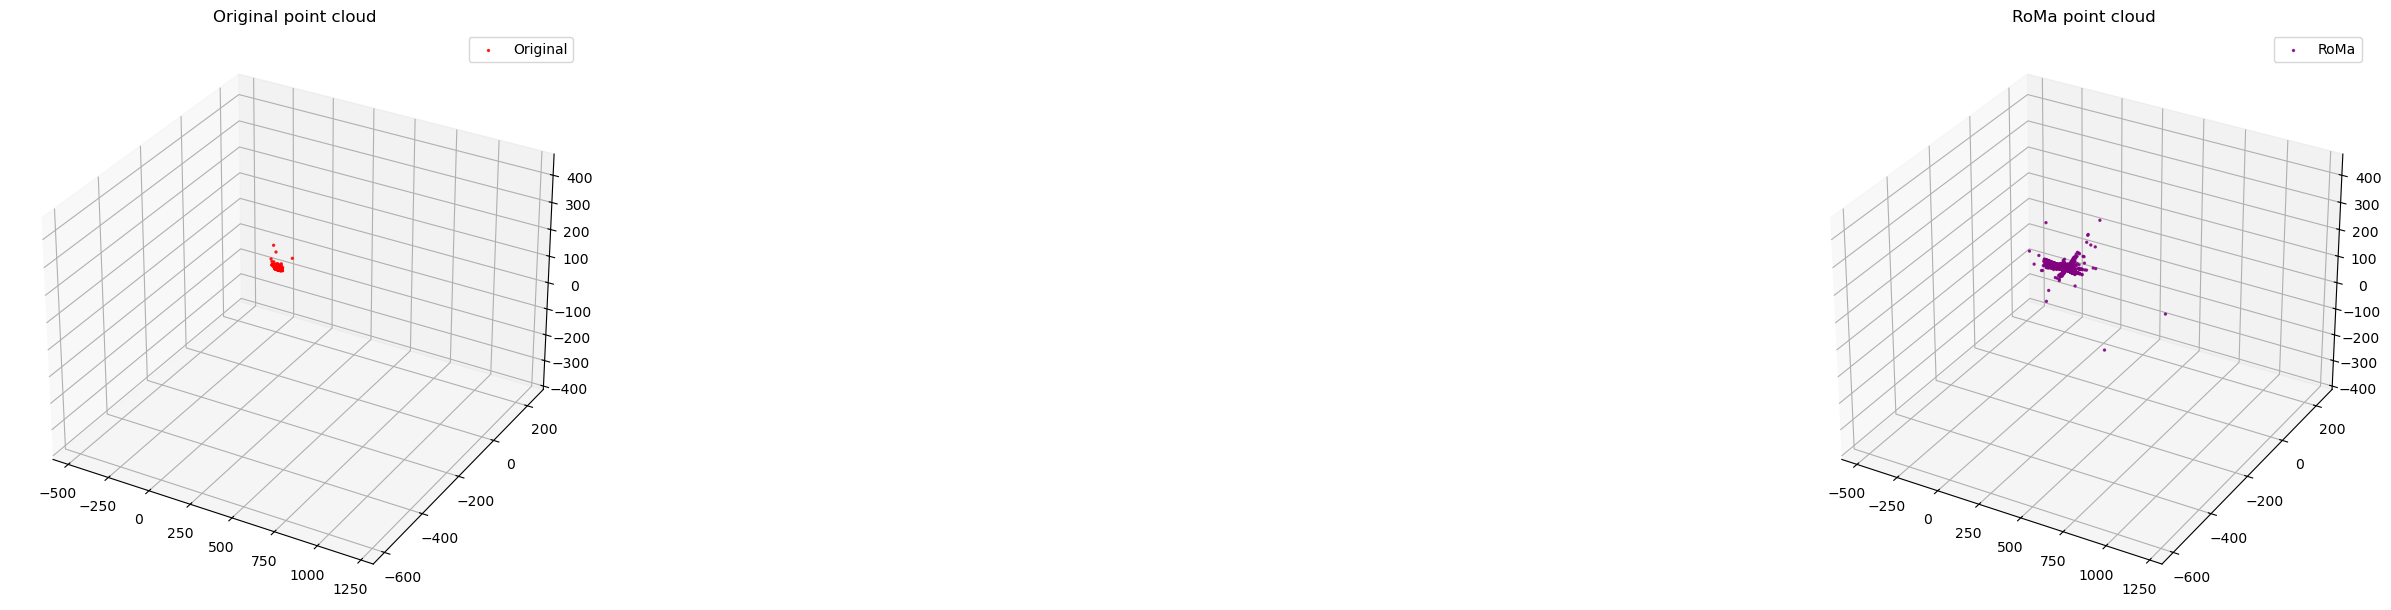

In [6]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np
import torch
from read_write_model import read_points3D_binary

# 读取原始点云
path_orig = "/home/yuzhou/Desktop/datasets/360_v2/bonsai/sparse/0/points3D.bin"
points3D_orig = read_points3D_binary(path_orig)
pts_np = np.array([p.xyz for p in points3D_orig.values()])

# 读取 RoMa 点云
path_roma = "/home/yuzhou/Desktop/datasets/360_v2/bonsai/sparse/0/points3D_roma.bin"
points3D_roma = read_points3D_binary(path_roma)
roma_np = np.array([p.xyz for p in points3D_roma.values()])


# 统一坐标范围
mins = np.min(np.vstack([pts_np, roma_np]), axis=0)
maxs = np.max(np.vstack([pts_np, roma_np]), axis=0)

def set_axes_equal(ax, mins, maxs):
    ax.set_xlim(mins[0], maxs[0])
    ax.set_ylim(mins[1], maxs[1])
    ax.set_zlim(mins[2], maxs[2])

# 四张子图
fig = plt.figure(figsize=(24,6))

# 原始点云
ax0 = fig.add_subplot(141, projection="3d")
ax0.scatter(pts_np[:,0], pts_np[:,1], pts_np[:,2], s=2, c="red", alpha=0.8, label="Original")
set_axes_equal(ax0, mins, maxs)
ax0.set_title("Original point cloud")
ax0.legend()

# RoMa 点云
ax3 = fig.add_subplot(144, projection="3d")
ax3.scatter(roma_np[:,0], roma_np[:,1], roma_np[:,2], s=2, c="purple", alpha=0.8, label="RoMa")
set_axes_equal(ax3, mins, maxs)
ax3.set_title("RoMa point cloud")
ax3.legend()

plt.tight_layout()
plt.show()


In [20]:
np.max(np.linalg.norm(roma_np,axis=1), axis=0)

np.float64(0.4447124629713855)

In [22]:
roma_np

array([[-2.52224680e-07, -6.92152256e-08,  4.44688946e-01],
       [ 1.16821070e-07,  8.50118909e-08,  4.44689155e-01],
       [-8.75220906e-07, -5.96642849e-07,  4.44688737e-01],
       ...,
       [-6.04043535e-08, -4.35341008e-09,  4.44689035e-01],
       [-2.44656746e-07, -4.65852480e-07,  4.44689095e-01],
       [ 5.28522264e-07,  1.14512079e-06,  4.44689006e-01]],
      shape=(326606, 3))

In [15]:
import open3d as o3d

pcd = o3d.io.read_point_cloud("/home/yuzhou/Desktop/output/roma_edgs_points.ply")
o3d.visualization.draw_geometries([pcd])


In [23]:
import os
import numpy as np
import read_write_model

# ====== 四元数转旋转矩阵 ======
def qvec2rotmat(qvec):
    w, x, y, z = qvec
    return np.array([
        [1 - 2*y**2 - 2*z**2, 2*x*y - 2*z*w, 2*x*z + 2*y*w],
        [2*x*y + 2*z*w, 1 - 2*x**2 - 2*z**2, 2*y*z - 2*x*w],
        [2*x*z - 2*y*w, 2*y*z + 2*x*w, 1 - 2*x**2 - 2*y**2]
    ])

# ====== 三角化函数 ======
def triangulate_point(P1, P2, x1, y1, x2, y2):
    A = np.array([
        x1 * P1[2,:] - P1[0,:],
        y1 * P1[2,:] - P1[1,:],
        x2 * P2[2,:] - P2[0,:],
        y2 * P2[2,:] - P2[1,:]
    ])
    _, _, V = np.linalg.svd(A)
    X = V[-1]
    return X[:3] / X[3]

# ====== 主程序 ======
if __name__ == "__main__":
    colmap_sparse = "/home/yuzhou/Desktop/datasets/360_v2/bonsai/sparse/0"

    # 读相机和图像
    cameras = read_write_model.read_cameras_binary(os.path.join(colmap_sparse, "cameras.bin"))
    images = read_write_model.read_images_binary(os.path.join(colmap_sparse, "images.bin"))

    # 拿两张图
    img_items = list(images.items())
    img1 = img_items[0][1]
    img2 = img_items[1][1]

    cam1 = cameras[img1.camera_id]
    cam2 = cameras[img2.camera_id]

    # 内参矩阵
    K1 = np.array([[cam1.params[0], 0, cam1.params[2]],
                   [0, cam1.params[1], cam1.params[3]],
                   [0, 0, 1]])
    K2 = np.array([[cam2.params[0], 0, cam2.params[2]],
                   [0, cam2.params[1], cam2.params[3]],
                   [0, 0, 1]])

    # 外参
    R1 = qvec2rotmat(img1.qvec)
    t1 = img1.tvec.reshape(3,1)
    R2 = qvec2rotmat(img2.qvec)
    t2 = img2.tvec.reshape(3,1)

    P1 = K1 @ np.hstack([R1, t1])
    P2 = K2 @ np.hstack([R2, t2])

    print("P1 shape:", P1.shape, "P2 shape:", P2.shape)

    # 随便取几个像素点（图像宽高需要你填）
    W, H = cam1.width, cam1.height
    test_pixels = [(W/2, H/2), (W*0.3, H*0.4), (W*0.8, H*0.6)]

    for (u,v) in test_pixels:
        X = triangulate_point(P1, P2, u, v, u+5, v+5)  # 第二张图假设平移 5 个像素
        print(f"Pixel {(u,v)} -> 3D point {X}")


P1 shape: (3, 4) P2 shape: (3, 4)
Pixel (1559.0, 1039.0) -> 3D point [-0.17100712  1.43155124  1.7889193 ]
Pixel (935.4, 831.2) -> 3D point [-0.81091735  0.84141138  1.87499136]
Pixel (2494.4, 1246.8) -> 3D point [1.0979588  2.4914199  1.49468809]


In [ ]:
import numpy as np
import open3d as o3d

# 读取点云
pcd = o3d.io.read_point_cloud("/home/yuzhou/Desktop/output/roma_edgs_points.ply")
points = np.asarray(pcd.points)
colors = np.asarray(pcd.colors)

print("原始点数:", points.shape[0])
print("范围:", points.min(axis=0), points.max(axis=0))

# ==== 过滤逻辑 ====
# 设定一个阈值，比如 |x|,|y| > 100 的点去掉
points_filtered = points
colors_filtered = colors

print("过滤后点数:", points_filtered.shape[0])
print("范围:", points_filtered.min(axis=0), points_filtered.max(axis=0))

# 构建新的点云对象
pcd_filtered = o3d.geometry.PointCloud()
pcd_filtered.points = o3d.utility.Vector3dVector(points_filtered)
pcd_filtered.colors = o3d.utility.Vector3dVector(colors_filtered)

# 可视化
o3d.visualization.draw_geometries([pcd_filtered])


原始点数: 3526029
范围: [-1.34323987e+03 -9.30099243e+02 -1.28548638e+06] [581799.         669180.5625       1202.23303223]
过滤后点数: 3525166
范围: [-99.96075439 -67.11543274 -66.2589035 ] [68.64748383 79.96018982 44.65217209]


In [36]:
import os
import read_write_model  # 确保你的read_write_model.py在utils目录下

path = "/home/yuzhou/Desktop/datasets/360_v2/bonsai/sparse/0/cameras.bin"
cameras = read_write_model.read_cameras_binary(path)

print("共有相机数量:", len(cameras))
for cam_id, cam in cameras.items():
    print(f"--- Camera ID {cam_id} ---")
    print("Model:", cam.model)
    print("Width, Height:", cam.width, cam.height)
    print("Params:", cam.params)


共有相机数量: 1
--- Camera ID 1 ---
Model: PINHOLE
Width, Height: 3118 2078
Params: [3222.70107976 3222.70107976 1559.         1039.        ]


In [3]:
import os
import numpy as np
import open3d as o3d
from read_write_model import read_points3D_binary

colmap_dir = "/home/yuzhou/Desktop/datasets/360_v2/bonsai/sparse/0"
points_dict = read_points3D_binary(os.path.join(colmap_dir, "points3D.bin"))

# 提取 xyz + rgb
points = np.array([p.xyz for p in points_dict.values()])
colors = np.array([p.rgb for p in points_dict.values()]) / 255.0  # 归一化到 [0,1]

# 构建 Open3D 点云对象
pcd = o3d.geometry.PointCloud()
pcd.points = o3d.utility.Vector3dVector(points)
pcd.colors = o3d.utility.Vector3dVector(colors)

# 可视化
o3d.visualization.draw_geometries([pcd])


Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [4]:
import numpy as np
import imageio
import os
import torch
from torch.utils.data import Dataset
from torchvision import transforms
from read_write_model import read_images_binary, read_cameras_binary, read_points3D_binary, qvec2rotmat

# class LLFFDataset(Dataset):
#     def __init__(self, basedir, factor=8):
#         self.basedir = basedir
#         self.transform = transforms.ToTensor()
#         self._load_meta(factor)
#
#     def _load_meta(self, factor):
#         poses_bounds = np.load(os.path.join(self.basedir, "poses_bounds.npy"))
#         poses = poses_bounds[:, :-2].reshape([-1, 3, 5])
#         self.poses = poses[:, :, :4]
#         self.poses = torch.from_numpy(self.poses).float()
#         import pdb; pdb.set_trace()
#
#         image_dir = os.path.join(self.basedir, f"images_{factor}")
#         self.image_paths = sorted([
#             os.path.join(image_dir, f) for f in os.listdir(image_dir) if f.endswith(('JPG', 'jpg', 'png'))
#         ])
#         self.images = [self.transform(imageio.imread(p)) for p in self.image_paths]
#         self.images = torch.stack(self.images)
#
#         self.poses = self.poses[:1]
#         self.images = self.images[:1]
#         print(f"Loaded {len(self.images)} images from {image_dir}")
#
#     def __len__(self):
#         return len(self.images)
#
#     def __getitem__(self, idx):
#         img = self.images[idx]
#         pose = self.poses[idx]
#         rays_o, rays_d = self._get_rays(img.shape[1:], pose)
#         return rays_o.reshape(-1, 3), rays_d.reshape(-1, 3), img.permute(1, 2, 0).reshape(-1, 3)
#
#     def _get_rays(self, img_hw, c2w):
#         H, W = img_hw
#         i, j = torch.meshgrid(torch.arange(W), torch.arange(H), indexing="xy")
#         dirs = torch.stack([(i - W * 0.5) / W, -(j - H * 0.5) / H, -torch.ones_like(i)], -1)
#         rays_d = torch.sum(dirs[..., None, :] * c2w[:3, :3], -1)
#         rays_o = c2w[:3, 3].expand(rays_d.shape)
#         return rays_o, rays_d


class mip360Dataset(Dataset):
    def __init__(self, basedir, factor=8, llffhold=8, split='train'):
        self.basedir = basedir
        self.transform = transforms.ToTensor()
        self.llffhold = llffhold
        self.split = split
        self._load_meta(factor)

    def _load_meta(self, factor):
        # === 修改部分：从 COLMAP 读取 pose ===
        colmap_dir = os.path.join(self.basedir, "sparse/0")
        images = read_images_binary(os.path.join(colmap_dir, "images.bin"))
        cameras = read_cameras_binary(os.path.join(colmap_dir, "cameras.bin"))

        image_ids_sorted = sorted(images.keys())

        poses = []
        hwf_list = []
        for image_id in image_ids_sorted:
            image = images[image_id]
            cam = cameras[image.camera_id]

            # pose: w2c → c2w
            R = qvec2rotmat(image.qvec)
            t = image.tvec.reshape(3,)
            c2w = np.eye(4)
            c2w[:3, :3] = R.T
            c2w[:3, 3] = -R.T @ t
            poses.append(c2w[:3, :4])

            # intrinsic: assume fx = fy
            H, W = cam.height, cam.width
            fx = cam.params[0]
            hwf_list.append([H, W, fx])

        poses = np.stack(poses, axis=0)         # (N, 3, 4)
        hwf = np.array(hwf_list)                # (N, 3)

        # === 归一化位姿（保持原逻辑）===
        positions = poses[:, :, 3]
        avg_position = np.mean(positions, axis=0)
        dists = np.linalg.norm(positions - avg_position, axis=1)
        scale = 1.0 / (np.max(dists) * 0.75)  # 0.75是典型缩放因子

        poses[:, :, 3] -= avg_position
        poses[:, :, 3] *= scale

        self.poses = torch.from_numpy(poses).float()


        # === 加载并归一化 COLMAP 点云 ===
        points3D = read_points3D_binary(os.path.join(colmap_dir, "points3D.bin"))
        all_xyz = []

        for pid in sorted(points3D.keys()):
            xyz = points3D[pid].xyz
            all_xyz.append(xyz)

        all_xyz = np.stack(all_xyz, axis=0)  # shape: (M, 3)

        # === 同样归一化（平移 + 缩放）===
        all_xyz -= avg_position
        all_xyz *= scale


        
        print("scale", scale)
        print("scale", scale)
        print("scale", scale)
        print("scale", scale)

        self.positions = torch.from_numpy(all_xyz).float()  # shape: (M, 3)


        # === 原封不动保留其余部分 ===

        # 读取图片
        if factor == 1:
            image_dir = os.path.join(self.basedir, f"images")
        else:
            image_dir = os.path.join(self.basedir, f"images_{factor}")
        self.image_paths = sorted([
            os.path.join(image_dir, f) for f in os.listdir(image_dir) if f.endswith(('JPG', 'jpg', 'png'))
        ])
        self.images = [self.transform(imageio.imread(p)) for p in self.image_paths]
        self.images = torch.stack(self.images)

        # 保存归一化参数用于后续处理
        self.scale = scale
        self.avg_position = avg_position

        # 计算焦距（从 hwf 获取）
        self.focal = hwf[0, 2] / factor  # 根据下采样因子调整焦距


        # === 按 llffhold 做 train/test 划分 ===
        num_images = self.images.shape[0]
        i_test = np.arange(num_images)[::self.llffhold]
        i_train = np.array([i for i in range(num_images) if i not in i_test])


        if self.split == 'train':
            select_ids = i_train
        elif self.split == 'test':
            select_ids = i_test
        else:
            raise ValueError(f"Unknown split type: {self.split}")

        # Apply split
        self.images = self.images[select_ids]
        self.poses = self.poses[select_ids]

        print(f"Loaded {len(self.images)} images from {image_dir}")


    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = self.images[idx]
        pose = self.poses[idx]
        rays_o, rays_d = self._get_rays(img.shape[1:], pose)
        #return rays_o.reshape(-1, 3), rays_d.reshape(-1, 3), img.permute(1, 2, 0).reshape(-1, 3)
        return rays_o, rays_d, img.permute(1, 2, 0)

    def _get_rays(self, img_hw, c2w):
        H, W = img_hw
        i, j = torch.meshgrid(torch.arange(W), torch.arange(H), indexing="xy")

        dirs = torch.stack([
            (i - W * 0.5) / self.focal,
            (j - H * 0.5) / self.focal,
            torch.ones_like(i)  # 🔁 z 是正方向
        ], -1)  # shape: (H, W, 3)

        # Rotate ray directions from camera to world
        rays_d = torch.sum(dirs[..., None, :] * c2w[:3, :3], -1)
        rays_o = c2w[:3, 3].expand(rays_d.shape)

        return rays_o, rays_d
    

    def get_all_rays(self, device=None, return_img_ids=False):
        """
        默认放在 CPU；只有当你显式传入 device（如 'cuda'）时才会搬过去。
        """
        rays_o_list, rays_d_list, rgbs_list = [], [], []
        img_id_list = [] if return_img_ids else None

        for i in range(len(self.images)):
            img  = self.images[i]                 # (3, H, W)
            pose = self.poses[i]                  # (3, 4)
            H, W = img.shape[1:]

            rays_o, rays_d = self._get_rays((H, W), pose)  # (H, W, 3)
            rays_o = rays_o.reshape(-1, 3)
            rays_d = rays_d.reshape(-1, 3)
            rgbs   = img.permute(1, 2, 0).reshape(-1, 3)

            rays_o_list.append(rays_o)
            rays_d_list.append(rays_d)
            rgbs_list.append(rgbs)

            if return_img_ids:
                img_id_list.append(torch.full((H * W,), i, dtype=torch.long))

        rays_o = torch.cat(rays_o_list, dim=0)
        rays_d = torch.cat(rays_d_list, dim=0)
        rgbs   = torch.cat(rgbs_list,   dim=0)

        if return_img_ids:
            img_ids = torch.cat(img_id_list, dim=0)

        # 只有当你想放到 GPU 时才传 device
        if device is not None:
            rays_o = rays_o.to(device, non_blocking=True)
            rays_d = rays_d.to(device, non_blocking=True)
            rgbs   = rgbs.to(device, non_blocking=True)
            if return_img_ids:
                img_ids = img_ids.to(device, non_blocking=True)

        if return_img_ids:
            return rays_o, rays_d, rgbs, img_ids
        return rays_o, rays_d, rgbs


In [5]:
data_dir = "/home/yuzhou/Desktop/datasets/360_v2/bonsai"
dataset = mip360Dataset(data_dir)
dataset.positions.mean(axis=0)

scale 0.2839294226514432
scale 0.2839294226514432
scale 0.2839294226514432
scale 0.2839294226514432


/tmp/ipykernel_2648655/3925061605.py:135: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  self.images = [self.transform(imageio.imread(p)) for p in self.image_paths]


Loaded 255 images from /home/yuzhou/Desktop/datasets/360_v2/bonsai/images_8


tensor([-0.2784,  0.6927,  1.0494])